In [4]:
#Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from sklearn.inspection import permutation_importance

In [7]:
df=pd.read_csv('data_pelanggan.csv')
df

,id_pelanggan,usia,lama_langganan_bulan,tagihan_bulanan_ribu,jumlah_keluhan,frekuensi_login_per_bulan,paket,churn
0,P0001,22,7,222.0,1,13,Premium,1
1,P0002,55,40,155.0,2,19,Standard,0
2,P0003,49,58,179.0,2,10,Standard,1
3,P0004,39,53,147.0,3,0,Basic,0
4,P0005,38,17,141.0,2,2,Basic,1
...,...,...,...,...,...,...,...,...
495,P0496,37,38,205.0,1,25,Standard,0
496,P0497,23,32,129.0,4,29,Standard,1
497,P0498,35,22,79.0,2,1,Basic,1
498,P0499,62,58,172.0,1,9,Standard,0


In [9]:
# 2. Siapkan fitur (kolom 'paket' diubah jadi angka dengan one-hot encoding)
X = pd.get_dummies(df.drop(columns=["id_pelanggan", "churn"]), columns=["paket"])
y = df["churn"]
df

,id_pelanggan,usia,lama_langganan_bulan,tagihan_bulanan_ribu,jumlah_keluhan,frekuensi_login_per_bulan,paket,churn
0,P0001,22,7,222.0,1,13,Premium,1
1,P0002,55,40,155.0,2,19,Standard,0
2,P0003,49,58,179.0,2,10,Standard,1
3,P0004,39,53,147.0,3,0,Basic,0
4,P0005,38,17,141.0,2,2,Basic,1
...,...,...,...,...,...,...,...,...
495,P0496,37,38,205.0,1,25,Standard,0
496,P0497,23,32,129.0,4,29,Standard,1
497,P0498,35,22,79.0,2,1,Basic,1
498,P0499,62,58,172.0,1,9,Standard,0


In [10]:
# 3. Bagi data: 80% latih, 20% uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
# 4. Latih model
rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3,
                            oob_score=True, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=6, min_samples_leaf=3, n_estimators=300,
                       n_jobs=-1, oob_score=True, random_state=42)

In [12]:
# 5. Evaluasi
pred = rf.predict(X_test)
proba = rf.predict_proba(X_test)[:, 1]
print(f"OOB score   : {rf.oob_score_:.3f}")
print(f"Akurasi uji : {accuracy_score(y_test, pred):.3f}")
print(f"ROC AUC     : {roc_auc_score(y_test, proba):.3f}")
print(classification_report(y_test, pred, target_names=["Bertahan", "Churn"]))


OOB score   : 0.745
Akurasi uji : 0.740
ROC AUC     : 0.822
              precision    recall  f1-score   support

    Bertahan       0.74      0.76      0.75        51
       Churn       0.74      0.71      0.73        49

    accuracy                           0.74       100
   macro avg       0.74      0.74      0.74       100
weighted avg       0.74      0.74      0.74       100



Dari 100 data uji, model menebak benar 74 pelanggan. Rinciannya, 39 bertahan dan 35 churn ditebak benar, sedangkan 12 pelanggan bertahan salah ditebak churn dan 14 pelanggan churn terlewat. Precision dan recall kedua kelas sama-sama sekitar 0,71 sampai 0,76, jadi model tidak berat sebelah.

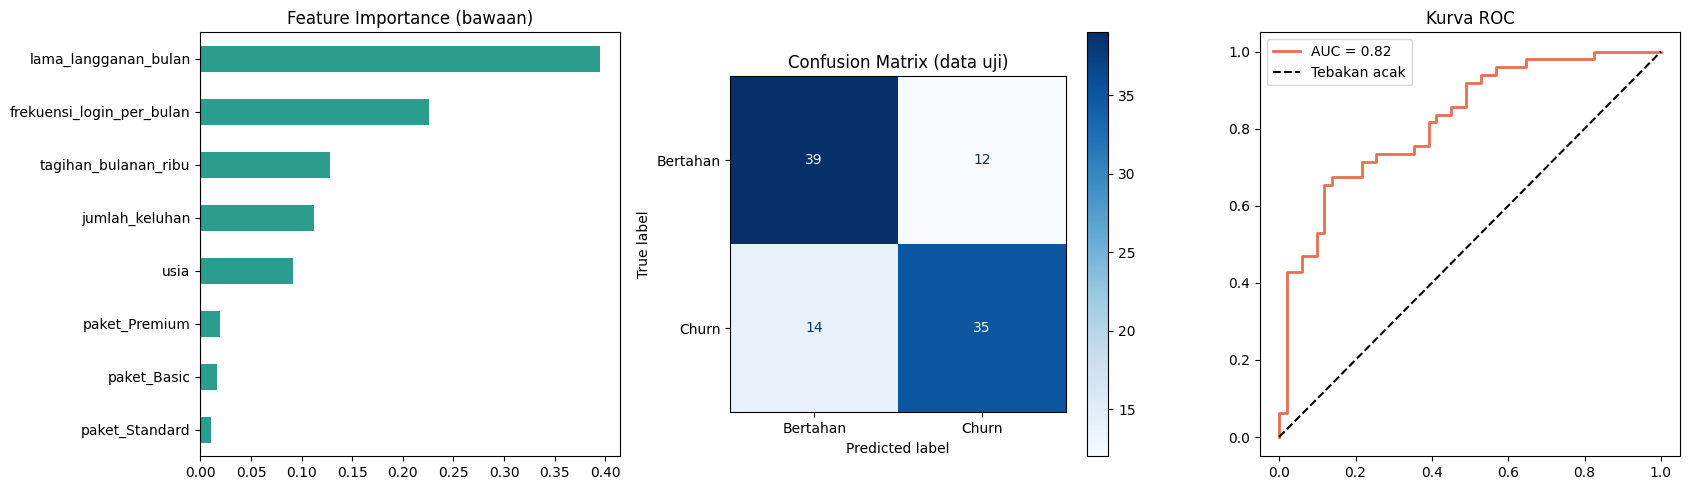

In [14]:
# 6. Grafik: importance, confusion matrix, ROC
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(ax=ax[0], color="#2a9d8f")
ax[0].set_title("Feature Importance (bawaan)")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Bertahan", "Churn"], cmap="Blues", ax=ax[1])
ax[1].set_title("Confusion Matrix (data uji)")

fpr, tpr, _ = roc_curve(y_test, proba)
ax[2].plot(fpr, tpr, color="#e76f51", lw=2, label=f"AUC = {roc_auc_score(y_test, proba):.2f}")
ax[2].plot([0, 1], [0, 1], "k--", label="Tebakan acak")
ax[2].set_title("Kurva ROC")
ax[2].legend()

plt.tight_layout()
plt.savefig("hasil_random_forest.png", dpi=130)



Feature Importance (kiri). lama_langganan_bulan paling berpengaruh (sekitar 0,40), disusul frekuensi_login_per_bulan (sekitar 0,23). Pelanggan lama dan yang rajin login cenderung bertahan.
Confusion Matrix (tengah). Diagonal (39 dan 35) adalah tebakan benar, sedangkan kotak lainnya (12 dan 14) adalah salah tebak.
Kurva ROC (kanan). Makin melengkung ke pojok kiri atas, makin bagus. AUC 0,82 artinya jika kita ambil satu pelanggan churn dan satu yang bertahan secara acak, model memberi skor lebih tinggi ke yang churn dalam sekitar 82% kasus. Garis putus-putus adalah tebakan acak (AUC 0,5).

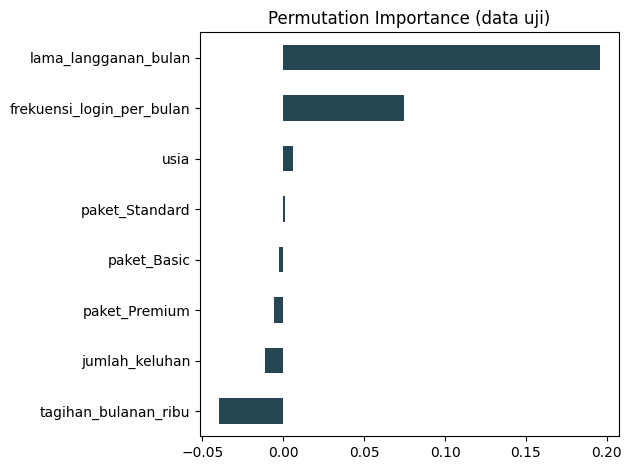

In [15]:
# 7. Permutation importance (lebih adil dibanding bawaan)
r = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1)
pd.Series(r.importances_mean, index=X.columns).sort_values().plot.barh(color="#264653")
plt.title("Permutation Importance (data uji)")
plt.tight_layout()
plt.savefig("permutation_importance.png", dpi=130)

Hasil bawaan dan permutation importance tidak sepenuhnya sejalan. Keduanya sepakat bahwa lama_langganan_bulan (0,196) dan frekuensi_login_per_bulan (0,074) yang paling penting. Tapi tagihan_bulanan_ribu dan jumlah_keluhan terlihat cukup penting di grafik bawaan, sedangkan di permutation importance nilainya mendekati nol atau negatif. Artinya pada data uji, mengacak kedua fitur itu tidak menurunkan akurasi. Ini contoh bias importance bawaan terhadap fitur bernilai banyak, dan datanya juga hanya 100 baris sehingga hasilnya berisik. Karena jumlah_keluhan sebenarnya ikut dipakai saat membuat data, model dengan 500 baris belum sepenuhnya menangkap pengaruhnya.